# SemEval-2016 climate: EDA and TF-IDF baseline

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

This notebook explores the English SemEval-2016 Task 6 tweets on the target *"Climate Change is a Real Concern"*
(`data/external/semeval_climate.csv`, written by `scripts/download_external.py`) and runs a TF-IDF + Logistic
Regression baseline on the official train/validation/test split. It exists to check the EDA and baseline pipeline
end to end before the official Hindi/Bengali data is released. None of the numbers here are TerraLens results.

Figures are saved to `reports/figures/` and a summary to `reports/eda_semeval.md`.

## 0. Setup

In [1]:
import json
import random
import re
from collections import Counter
from pathlib import Path

import emoji
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.pipeline import Pipeline

from terralens import LABELS
from terralens.baselines import build_features, load_config
from terralens.data import PROJECT_ROOT, load_external
from terralens.evaluate import against_f1, confusion_df, macro_f1
from terralens.preprocess import MENTION_RE, URL_RE, clean_text

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DISCLAIMER = "English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results."
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SPLITS = ["train", "validation", "test"]
PALETTE = {"Favour": "#2a9d8f", "Against": "#e76f51", "None": "#8d99ae"}

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)


def save_fig(fig, name):
    """Stamp the disclaimer on a figure and save it to reports/figures/."""
    fig.text(0.5, 0.005, DISCLAIMER, ha="center", va="bottom", fontsize=8, color="#b00020", style="italic")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path.relative_to(PROJECT_ROOT)}")
    return path

## 1. Load data and row counts per split

The repo's loader keeps the string `"None"` as a label (plain `pd.read_csv` would turn it into NaN).

In [2]:
df = load_external("semeval_climate")
df["split"] = pd.Categorical(df["split"], categories=SPLITS, ordered=True)
assert df["label"].notna().all() and set(df["label"]) <= set(LABELS)

print(DISCLAIMER)
print(f"{len(df)} tweets, columns: {list(df.columns)}\n")
split_counts = pd.crosstab(df["split"], df["label"], margins=True, margins_name="total")[LABELS + ["total"]]
split_counts

English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.
564 tweets, columns: ['id', 'text', 'label', 'source', 'lang', 'split']



label,Favour,Against,None,total
split,,,,
train,191,13,151,355
validation,21,2,17,40
test,123,11,35,169
total,335,26,203,564


saved reports\figures\semeval_label_distribution.png


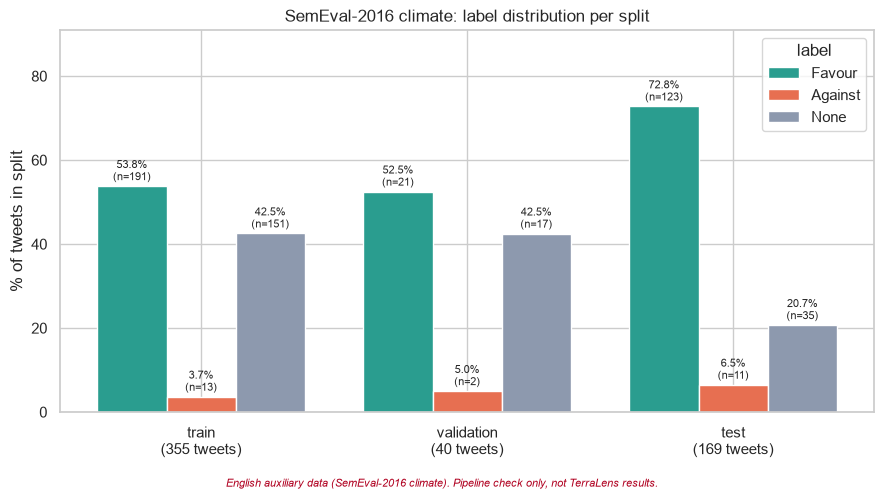

In [3]:
pct = pd.crosstab(df["split"], df["label"], normalize="index")[LABELS] * 100

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(SPLITS))
w = 0.26
for i, label in enumerate(LABELS):
    bars = ax.bar(x + (i - 1) * w, pct.loc[SPLITS, label], w, label=label, color=PALETTE[label])
    counts = split_counts.loc[SPLITS, label]
    for b, p, n in zip(bars, pct.loc[SPLITS, label], counts):
        ax.annotate(f"{p:.1f}%\n(n={n})", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
ax.set_xticks(x, [f"{s}\n({split_counts.loc[s, 'total']} tweets)" for s in SPLITS])
ax.set_ylabel("% of tweets in split")
ax.set_ylim(0, pct.values.max() * 1.25)
ax.set_title("SemEval-2016 climate: label distribution per split")
ax.legend(title="label")
save_fig(fig, "semeval_label_distribution.png")
plt.show()

## 2. Tweet length (word count)

saved reports\figures\semeval_word_count_hist.png


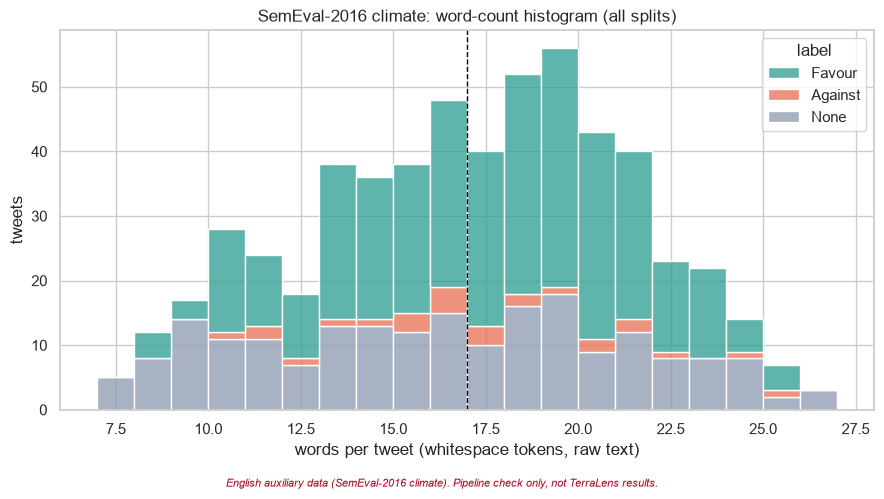

,count,mean,median,min,max
label,,,,,
Favour,335,17.01,17.0,8,25
Against,26,16.88,16.5,10,25
None,203,15.88,16.0,7,27


In [4]:
df["n_words"] = df["text"].str.split().str.len()

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="n_words", hue="label", hue_order=LABELS, palette=PALETTE,
             multiple="stack", binwidth=1, ax=ax)
ax.axvline(df["n_words"].median(), color="black", ls="--", lw=1, label="median")
ax.set_xlabel("words per tweet (whitespace tokens, raw text)")
ax.set_ylabel("tweets")
ax.set_title("SemEval-2016 climate: word-count histogram (all splits)")
save_fig(fig, "semeval_word_count_hist.png")
plt.show()

length_stats = df.groupby("label")["n_words"].agg(["count", "mean", "median", "min", "max"]).reindex(LABELS).round(2)
length_stats

## 3. Top 15 words per label

Lower-cased; URLs, @mentions and `#SemST` (the dataset's collection tag, present in almost every tweet) removed;
English stopwords (scikit-learn list), tokens shorter than 2 characters and pure numbers dropped.
Other hashtags are kept as words (`#climate` → `climate`).

saved reports\figures\semeval_top_words.png


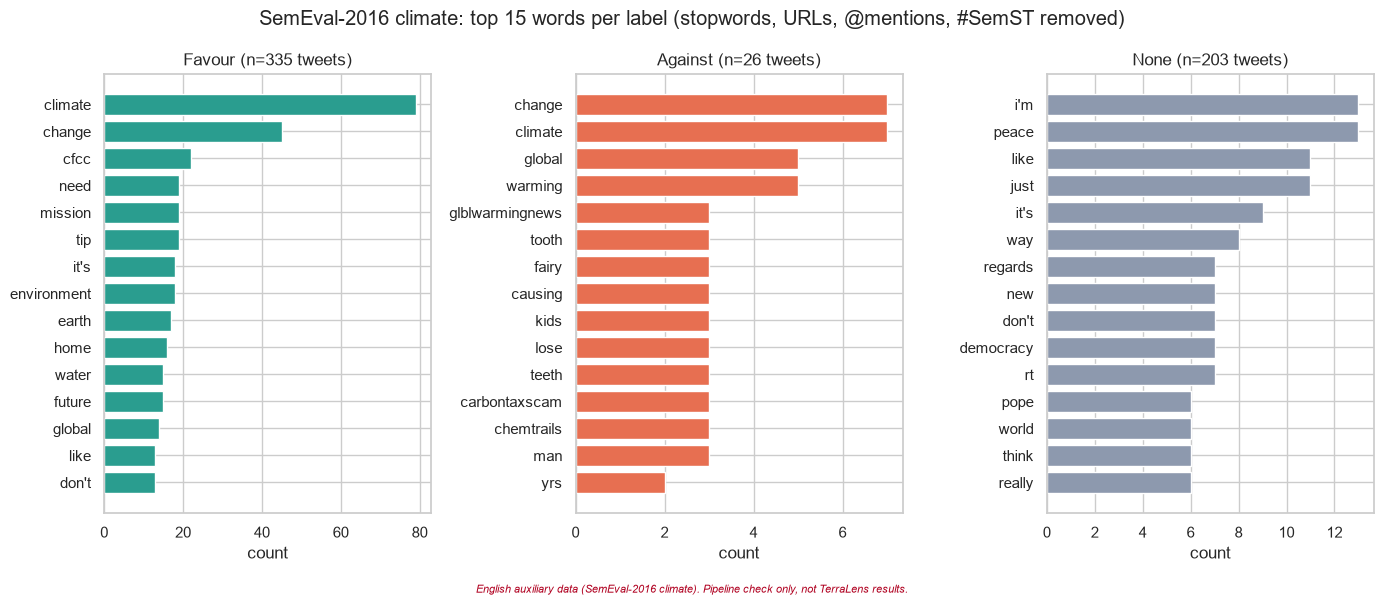

,Favour,Against,None
0,climate (79),change (7),i'm (13)
1,change (45),climate (7),peace (13)
2,cfcc (22),global (5),like (11)
3,need (19),warming (5),just (11)
4,mission (19),glblwarmingnews (3),it's (9)
5,tip (19),tooth (3),way (8)
6,it's (18),fairy (3),regards (7)
7,environment (18),causing (3),new (7)
8,earth (17),kids (3),don't (7)
9,home (16),lose (3),democracy (7)


In [5]:
SEMST_RE = re.compile(r"#semst\b", re.IGNORECASE)
TOKEN_RE = re.compile(r"[a-z][a-z']+")


def tokens_for_counts(text):
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = SEMST_RE.sub(" ", text)
    toks = TOKEN_RE.findall(text.lower())
    toks = [t.strip("'") for t in toks]
    return [t for t in toks if len(t) > 1 and t not in ENGLISH_STOP_WORDS]


top_words = {label: Counter(t for txt in df.loc[df.label == label, "text"] for t in tokens_for_counts(txt)).most_common(15)
             for label in LABELS}

fig, axes = plt.subplots(1, 3, figsize=(14, 6))
for ax, label in zip(axes, LABELS):
    words, counts = zip(*top_words[label])
    ax.barh(words[::-1], counts[::-1], color=PALETTE[label])
    ax.set_title(f"{label} (n={int((df.label == label).sum())} tweets)")
    ax.set_xlabel("count")
fig.suptitle("SemEval-2016 climate: top 15 words per label (stopwords, URLs, @mentions, #SemST removed)")
save_fig(fig, "semeval_top_words.png")
plt.show()

pd.DataFrame({label: [f"{w} ({c})" for w, c in top_words[label]] for label in LABELS})

## 4. Noise inventory: emojis, hashtags, URLs, mentions

Note: the `tweet_eval` copy masks handles as `@user` and has URLs and emojis stripped upstream.

In [6]:
HASHTAG_RE = re.compile(r"#\w+")

noise = pd.DataFrame({
    "emoji": df["text"].map(lambda t: emoji.emoji_count(t) > 0),
    "hashtag (any)": df["text"].map(lambda t: bool(HASHTAG_RE.search(t))),
    "hashtag (excl. #SemST)": df["text"].map(lambda t: bool(HASHTAG_RE.search(SEMST_RE.sub(" ", t)))),
    "#SemST": df["text"].map(lambda t: bool(SEMST_RE.search(t))),
    "URL": df["text"].map(lambda t: bool(URL_RE.search(t))),
    "@mention": df["text"].map(lambda t: bool(MENTION_RE.search(t))),
})
noise_summary = pd.DataFrame({"tweets": noise.sum(), "% of all": (noise.mean() * 100).round(1)})
noise_by_label = noise.groupby(df["label"]).mean().reindex(LABELS).T.mul(100).round(1).add_suffix(" %")
noise_summary.join(noise_by_label)

,tweets,% of all,Favour %,Against %,None %
emoji,0,0.0,0.0,0.0,0.0
hashtag (any),564,100.0,100.0,100.0,100.0
hashtag (excl. #SemST),402,71.3,75.8,65.4,64.5
#SemST,564,100.0,100.0,100.0,100.0
URL,0,0.0,0.0,0.0,0.0
@mention,227,40.2,35.5,23.1,50.2


## 5. Three random example tweets per label

In [7]:
for label in LABELS:
    print(f"=== {label} ===")
    for t in df[df.label == label].sample(3, random_state=SEED)["text"]:
        print(" -", t)
    print()

=== Favour ===
 - Tonight - Academy of Science talk Tech solutions for climate change with Prof. Barry Brook #cantorandballtowers #Canberra #SemST
 - Every human commits original sin with it's first outbreath of CO2. Mankind is fallen. #bible #SemST
 - Look out for the hashtag #UKClimate2015 for news today on how the UK is doing in both reducing emissions and adapting to #SemST

=== Against ===
 - RedScareBot: Simple Malarkey RT gingerdr Global Warming/Climate Change all a HOAX. Communist agenda for control #sustainabil... #SemST
 - @user Still a larval theory. Still poorly modelled. Still unquantified. Still multi-factor. Still flummoxed by albedo. #SemST
 - tsgtalexander: GlblWarmingNews And the tooth fairy might be causing kids to lose teeth! #carbontaxscam #Chemtrails #SemST

=== None ===
 - @user @user @user @user Further proof of #SemST
 - @user wow that is certainly an extreme prognostication! #gop #libertarian #SemST
 - Why is there no #CaptainPlanet movie??? Rt if u want one. 

## 6. Baseline: TF-IDF (word 1-2 + char 2-5) + Logistic Regression

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

* Train on **train + validation** (395 tweets), evaluate once on **test** (169 tweets). No tuning on test.
* Text goes through the project's `clean_text` (URLs, mentions removed, emoji → text, lower-cased), plus removal of
  `#SemST`, which carries no label information.
* Features: `FeatureUnion` of word 1-2-gram and char_wb 2-5-gram TF-IDF, using the vectoriser settings from
  `configs/baseline.yaml` (`min_df=2`, `sublinear_tf=True`).
* Classifier: `LogisticRegression(class_weight="balanced", max_iter=1000)`.

In [8]:
def prep(text):
    return clean_text(SEMST_RE.sub(" ", text), lowercase=True)


df["clean_text"] = df["text"].map(prep)
train = df[df.split.isin(["train", "validation"])]
test = df[df.split == "test"]
X_train, y_train = train["clean_text"].to_numpy(), train["label"].to_numpy()
X_test, y_test = test["clean_text"].to_numpy(), test["label"].to_numpy()
print(f"train+validation: {len(train)}  {train.label.value_counts().reindex(LABELS).to_dict()}")
print(f"test:             {len(test)}  {test.label.value_counts().reindex(LABELS).to_dict()}")

config = load_config(PROJECT_ROOT / "configs" / "baseline.yaml")
lr_model = Pipeline([
    ("tfidf", build_features(config["features"])),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print("feature dims:", {name: len(v.vocabulary_) for name, v in lr_model.named_steps["tfidf"].transformer_list})

train+validation: 395  {'Favour': 212, 'Against': 15, 'None': 168}
test:             169  {'Favour': 123, 'Against': 11, 'None': 35}


feature dims: {'word': 1020, 'char': 9555}


## 7. Majority-class baseline

In [9]:
majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
maj_pred = majority.predict(X_test)
print("majority class:", majority.classes_[np.argmax(majority.class_prior_)])

majority class: Favour


## 8. Results on test

> **English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.**

In [10]:
results = {}
for name, pred in [("Majority class", maj_pred), ("TF-IDF + LR", lr_pred)]:
    results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "macro_f1": macro_f1(y_test, pred),
        "against_f1": against_f1(y_test, pred),
    }
    print(f"===== {name} =====  ({DISCLAIMER})")
    print(classification_report(y_test, pred, labels=LABELS, digits=3, zero_division=0))
    print(f"Against-class F1: {results[name]['against_f1']:.3f}\n")

results_df = pd.DataFrame(results).T.round(3)
results_df

===== Majority class =====  (English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.)
              precision    recall  f1-score   support

      Favour      0.728     1.000     0.842       123
     Against      0.000     0.000     0.000        11
        None      0.000     0.000     0.000        35

    accuracy                          0.728       169
   macro avg      0.243     0.333     0.281       169
weighted avg      0.530     0.728     0.613       169

Against-class F1: 0.000

===== TF-IDF + LR =====  (English auxiliary data (SemEval-2016 climate). Pipeline check only, not TerraLens results.)
              precision    recall  f1-score   support

      Favour      0.795     0.821     0.808       123
     Against      0.000     0.000     0.000        11
        None      0.415     0.486     0.447        35

    accuracy                          0.698       169
   macro avg      0.403     0.436     0.418       169
weighted avg      0.665     0

,accuracy,macro_f1,against_f1
Majority class,0.728,0.281,0.0
TF-IDF + LR,0.698,0.418,0.0


saved reports\figures\semeval_confusion_matrix.png


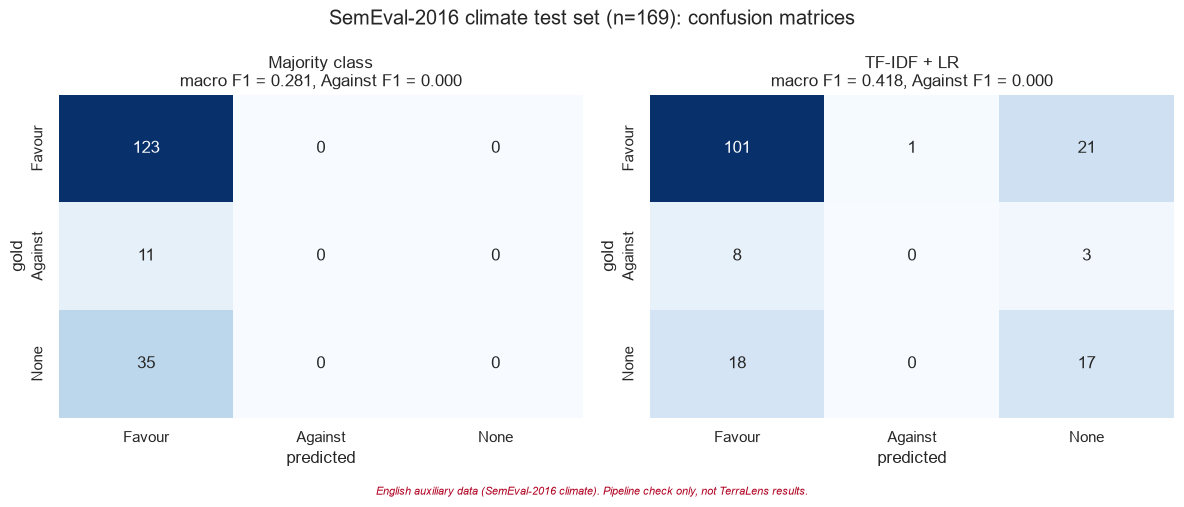

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pred) in zip(axes, [("Majority class", maj_pred), ("TF-IDF + LR", lr_pred)]):
    cm = confusion_df(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 12})
    ax.set_xlabel("predicted")
    ax.set_ylabel("gold")
    ax.set_title(f"{name}\nmacro F1 = {results[name]['macro_f1']:.3f}, Against F1 = {results[name]['against_f1']:.3f}")
fig.suptitle("SemEval-2016 climate test set (n=169): confusion matrices")
save_fig(fig, "semeval_confusion_matrix.png")
plt.show()

## 9. Top 10 most informative features per class (LR)

Largest positive coefficients for each class in the multinomial LR. `w:` = word n-gram, `c:` = char n-gram
(spaces shown as `␣`).

saved reports\figures\semeval_lr_top_features.png


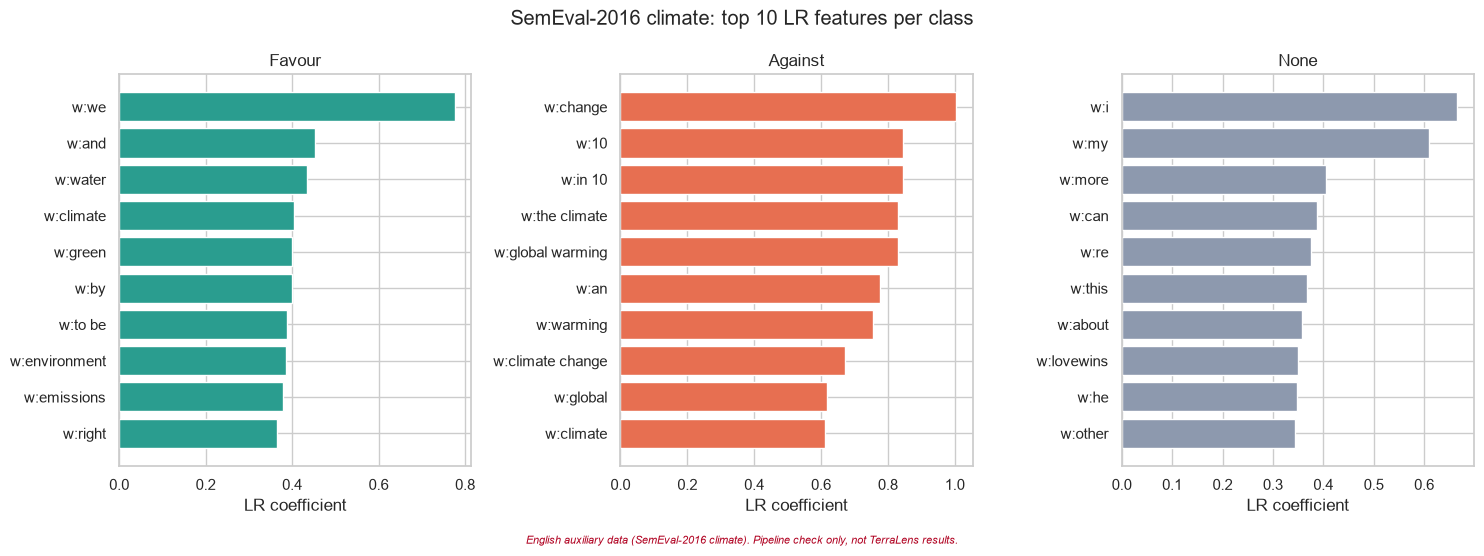

,Favour,Against,None
0,w:we (0.776),w:change (1.003),w:i (0.666)
1,w:and (0.452),w:10 (0.844),w:my (0.61)
2,w:water (0.434),w:in 10 (0.844),w:more (0.405)
3,w:climate (0.405),w:the climate (0.831),w:can (0.387)
4,w:green (0.401),w:global warming (0.829),w:re (0.376)
5,w:by (0.399),w:an (0.775),w:this (0.367)
6,w:to be (0.388),w:warming (0.755),w:about (0.358)
7,w:environment (0.386),w:climate change (0.673),w:lovewins (0.35)
8,w:emissions (0.378),w:global (0.618),w:he (0.348)
9,w:right (0.365),w:climate (0.612),w:other (0.344)


In [12]:
clf = lr_model.named_steps["clf"]
feat_names = np.concatenate([
    [f"{'w' if name == 'word' else 'c'}:{f}" for f in vec.get_feature_names_out()]
    for name, vec in lr_model.named_steps["tfidf"].transformer_list
])
feat_names = np.array([f.replace(" ", "␣") if f.startswith("c:") else f for f in feat_names])

top_feats = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, label in zip(axes, LABELS):
    k = list(clf.classes_).index(label)
    idx = np.argsort(clf.coef_[k])[::-1][:10]
    top_feats[label] = list(zip(feat_names[idx], clf.coef_[k][idx].round(3)))
    ax.barh(feat_names[idx][::-1], clf.coef_[k][idx][::-1], color=PALETTE[label])
    ax.set_title(label)
    ax.set_xlabel("LR coefficient")
fig.suptitle("SemEval-2016 climate: top 10 LR features per class")
save_fig(fig, "semeval_lr_top_features.png")
plt.show()

pd.DataFrame({label: [f"{f} ({c})" for f, c in top_feats[label]] for label in LABELS})

## 10. Write `reports/eda_semeval.md`

In [13]:
def md_table(frame):
    frame = frame.reset_index()
    head = "| " + " | ".join(map(str, frame.columns)) + " |"
    sep = "|" + "---|" * len(frame.columns)
    rows = ["| " + " | ".join(map(str, r)) + " |" for r in frame.itertuples(index=False)]
    return "\n".join([head, sep, *rows])


def fmt_words(pairs):
    return ", ".join(f"{w} ({c})" for w, c in pairs)


lr_rep = classification_report(y_test, lr_pred, labels=LABELS, output_dict=True, zero_division=0)
per_class = pd.DataFrame({l: lr_rep[l] for l in LABELS}).T[["precision", "recall", "f1-score", "support"]]
per_class["support"] = per_class["support"].astype(int)
per_class = per_class.round(3)
per_class.index.name = "class"

counts_tbl = split_counts.copy()
counts_tbl.index = counts_tbl.index.astype(str)
counts_tbl.index.name = "split"
counts_tbl.columns.name = None

lr_cm = confusion_df(y_test, lr_pred)
lr_cm.columns = [f"pred {c}" for c in lr_cm.columns]
r_lr, r_maj = results["TF-IDF + LR"], results["Majority class"]
res_tbl = results_df.copy()
res_tbl.index.name = "model"

report = f"""# SemEval-2016 climate: EDA and baseline summary

> **{DISCLAIMER}**
> These are English tweets used as auxiliary data. Nothing here measures performance on the Hindi/Bengali
> TerraLens task. Generated by `notebooks/01_eda_semeval.ipynb`.

## Data

`data/external/semeval_climate.csv`: {len(df)} English tweets on the target *"Climate Change is a Real Concern"*
(SemEval-2016 Task 6, via `cardiffnlp/tweet_eval` `stance_climate`).

{md_table(counts_tbl)}

![Label distribution per split](figures/semeval_label_distribution.png)

- **Against is tiny**: {int((df.label == 'Against').sum())} tweets overall ({(df.label == 'Against').mean():.1%}),
  and only {int((test.label == 'Against').sum())} in test, so Against-class metrics on this set are very noisy.
- Tweets are short: median {df.n_words.median():.0f} words, mean {df.n_words.mean():.1f}.

{md_table(length_stats.rename_axis("label"))}

![Word-count histogram](figures/semeval_word_count_hist.png)

**Noise.** {noise_summary.loc['#SemST', 'tweets']} tweets ({noise_summary.loc['#SemST', '% of all']}%) carry the `#SemST`
collection tag; {noise_summary.loc['hashtag (excl. #SemST)', '% of all']}% have another hashtag,
{noise_summary.loc['@mention', '% of all']}% an @mention, {noise_summary.loc['URL', '% of all']}% a URL and
{noise_summary.loc['emoji', '% of all']}% an emoji. The `tweet_eval` release is already pre-processed: user handles are
masked as `@user`, and URLs and emojis were stripped upstream, so the URL/emoji cleaning steps are not exercised here
(the YouTube comments will need them).

**Top words** (stopwords, URLs, @mentions, `#SemST` removed):

- Favour: {fmt_words(top_words['Favour'][:10])}
- Against: {fmt_words(top_words['Against'][:10])}
- None: {fmt_words(top_words['None'][:10])}

![Top words per label](figures/semeval_top_words.png)

## Baseline (train+validation → test)

TF-IDF word 1-2-grams + char_wb 2-5-grams (`FeatureUnion`, `min_df=2`, sublinear TF) + `LogisticRegression(class_weight="balanced", max_iter=1000)`,
compared with a majority-class (`Favour`) baseline. Trained on {len(train)} tweets, evaluated once on {len(test)} test tweets.

{md_table(res_tbl)}

TF-IDF + LR per-class results on test:

{md_table(per_class)}

**Against-class F1 (TF-IDF + LR): {r_lr['against_f1']:.3f}** (majority baseline: {r_maj['against_f1']:.3f}).

{md_table(lr_cm)}

![Confusion matrices](figures/semeval_confusion_matrix.png)

Top LR features per class:

- Favour: {', '.join(f for f, _ in top_feats['Favour'])}
- Against: {', '.join(f for f, _ in top_feats['Against'])}
- None: {', '.join(f for f, _ in top_feats['None'])}

![Top LR features](figures/semeval_lr_top_features.png)

## Takeaways

- The EDA → preprocessing → TF-IDF → LR → evaluation pipeline runs end to end and the figures and metrics are produced
  in the format planned for the official data.
- LR beats the majority baseline on macro F1 ({r_lr['macro_f1']:.3f} vs {r_maj['macro_f1']:.3f}).
- Against F1 is {r_lr['against_f1']:.3f}: LR predicted Against {int((lr_pred == 'Against').sum())} time(s) and recovered
  {int(((lr_pred == 'Against') & (y_test == 'Against')).sum())} of {int((test.label == 'Against').sum())} gold Against tweets. With only
  {int((train.label == 'Against').sum())} Against tweets in training, class weighting alone is not enough, and with
  {int((test.label == 'Against').sum())} in test a single prediction moves Against F1 a lot.
  SemEval climate is too small and too imbalanced to say much about the Against class; GWSD (400 Against) is the better
  English source for that.

*{DISCLAIMER}*
"""

out = PROJECT_ROOT / "reports" / "eda_semeval.md"
out.write_text(report, encoding="utf-8")
print(f"wrote {out.relative_to(PROJECT_ROOT)}")

wrote reports\eda_semeval.md
